# Pipeline NLP video pemrograman

**Data → audio → Whisper → cleaning → OCR lokal → Gemini → tokenisasi → mBART → evaluasi → hasil**

Notebook ini melatih Whisper untuk transkripsi dan membandingkan tiga strategi pelatihan mBART untuk peringkasan. Pada video utuh, tiga jalur memakai model peringkas yang sama untuk mengukur pengaruh konteks layar.

Pilih kernel Python 3.11 dari `.venv`, lalu klik **Run All**. Mode bawaan memutar ulang hasil yang disimpan. [Panduan menjalankan eksperimen](README.md)

## 01 · Mode dan lingkungan

In [1]:
import json
import os
from datetime import datetime
from pathlib import Path
import shutil
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "requirements-training.txt").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

MODE = os.environ.get("NLP_NOTEBOOK_MODE", "replay")
if MODE not in {"replay", "smoke", "pilot"}:
    raise ValueError("Gunakan replay, smoke, atau pilot.")
file = ROOT / "notebooks/Pipeline_NLP_Video_Pemrograman.ipynb"
replay = json.loads(file.read_text(encoding="utf-8"))["metadata"]["project_replay"]
RUN = ROOT / "outputs/notebooks/integrated" / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
SEED = 42
SPLITS = ("train", "validation", "test")
PALETTE = ["#627088", "#2858b8", "#b56d32"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 115})
print(f"Mode: {MODE} | Python {sys.version.split()[0]}")

from time import perf_counter
from matplotlib.ticker import PercentFormatter

TRAIN = MODE in {"smoke", "pilot"}
MBART_PYTHON = os.getenv("NLP_MBART_PYTHON", sys.executable)
MBART_DEVICE = os.getenv("NLP_MBART_DEVICE", "cpu")
GEMINI_LIMIT = int(os.getenv("NLP_GEMINI_MAX_REQUESTS", "0"))
if GEMINI_LIMIT < 0:
    raise ValueError("Batas permintaan Gemini harus nonnegatif.")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def execute(module, *args, python=sys.executable):
    subprocess.run([str(python), "-u", "-m", module, *map(str, args)], check=True, cwd=ROOT)

display(pd.Series({"Latih ulang": TRAIN, "Perangkat mBART saat latih": MBART_DEVICE,
                   "Batas panggilan Gemini": GEMINI_LIMIT, "Seed": SEED}))

Mode: replay | Python 3.11.15


Latih ulang                   False
Perangkat mBART saat latih      cpu
Batas panggilan Gemini            0
Seed                             42
dtype: object

- **Replay** membaca laporan tersimpan dan bisa dijalankan tanpa API.
- **Smoke** melatih satu epoch dengan subset kecil untuk memeriksa alur. **Pilot** memakai data lebih banyak dan hingga lima epoch untuk mengamati kurva validasi.
- Artefak baru memakai direktori eksekusi terpisah di `outputs/notebooks/integrated/`.

## 02 · Sumber data dan pembagian eksperimen

,train,validation,test
IndoSum,14261,750,3762
Tutorial coding,56,6,9
NSS-ID,112,12,24
Audio coding,20,12,12
LUMINA,24,12,12


,dataset,role,url
0,IndoSum,Benchmark peringkasan artikel Indonesia,https://github.com/kata-ai/indosum
1,Coding Video Mix · tutorial,"Teks dan ringkasan tutorial Indonesia, split p...",samples/coding_video_segments.json
2,Coding Video Mix · pilot sintetis,Contoh tambahan hanya pada train,scripts/prepare_coding_pilot.py
3,CrossTask,Tersedia sebagai contoh berbahasa Inggris. Di ...,https://github.com/DmZhukov/CrossTask#data
4,LUMINA v4,"Audio dan referensi resmi, split lokal per pen...",https://data.mendeley.com/datasets/8fw93k4rny/4
5,NSS-ID · Imperative,"Audio umum, split resmi per penutur",https://huggingface.co/datasets/Atika88/Indone...
6,Audio coding,"Klip tutorial, subtitle otomatis, split per video",scripts/prepare_whisper_video.py


,title,role,video_url
0,Break pada perulangan Python,Pengembangan,https://www.youtube.com/watch?v=B6scLunzn0I
1,Format string di Python,Uji eksploratif,https://www.youtube.com/watch?v=D66WxqZnjXg


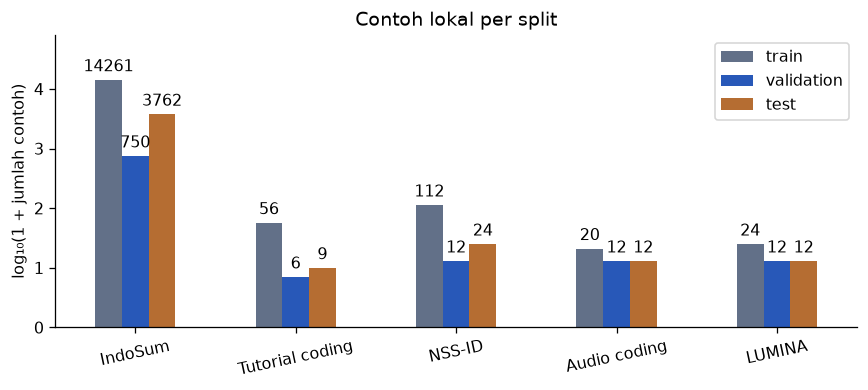

In [2]:
BASE = ROOT / "data/processed"
lumina_master = BASE / "lumina/test.csv"
if lumina_master.is_file() and any(not (BASE / "lumina_split" / f"{split}.csv").is_file() for split in SPLITS):
    from scripts.prepare_lumina_splits import split_lumina

    split_lumina(lumina_master, BASE / "lumina_split")
if MODE != "replay":
    for split in SPLITS:
        if not (BASE / "whisper_video" / f"{split}.csv").is_file():
            subprocess.run([sys.executable, "-m", "scripts.prepare_whisper_video", "--split", split], check=True)
sources = {
    "IndoSum": ("indosum", ("train", "validation", "test")),
    "Tutorial coding": ("coding_video_mix", ("train", "validation", "test")),
    "NSS-ID": ("nss-id", ("train", "val", "test")),
    "Audio coding": ("whisper_video", SPLITS),
    "LUMINA": ("lumina_split", SPLITS),
}
tables = {
    name: {role: pd.read_csv(path, dtype={"id": str}, keep_default_na=False)
           for role, file_split in zip(SPLITS, splits, strict=True)
           if (path := BASE / folder / f"{file_split}.csv").is_file()}
    for name, (folder, splits) in sources.items()
}
holdout = json.loads((ROOT / "samples/notebook_video_holdout.json").read_text(encoding="utf-8"))
holdout_ids = {video["id"] for video in holdout}
for name in ("Tutorial coding", "Audio coding"):
    known = set().union(*(set(df["video_id"]) - {""} for df in tables[name].values()))
    if known & holdout_ids:
        raise ValueError(f"Video akhir bertumpang tindih dengan {name}.")
group_keys = {"IndoSum": "id", "Tutorial coding": "video_id", "NSS-ID": "speaker_id",
              "Audio coding": "video_id", "LUMINA": "speaker_id"}
for name, column in group_keys.items():
    seen = set()
    for frame in tables[name].values():
        values = set(frame[column]) - {""}
        if seen & values:
            raise ValueError(f"{column} berulang antarsplit pada {name}.")
        seen |= values
counts = pd.DataFrame({name: {split: len(df) for split, df in frames.items()}
                       for name, frames in tables.items()}).T.reindex(columns=SPLITS)
display(counts.astype("Int64").astype(object).fillna("—"))

register = read_json(ROOT / "samples/summary_dataset_sources.json")
register += [
    {"dataset": "LUMINA v4", "role": "Audio dan referensi resmi, split lokal per penutur",
     "url": "https://data.mendeley.com/datasets/8fw93k4rny/4"},
    {"dataset": "NSS-ID · Imperative", "role": "Audio umum, split resmi per penutur",
     "url": "https://huggingface.co/datasets/Atika88/Indonesian-ASR-11-Class-Dataset"},
    {"dataset": "Audio coding", "role": "Klip tutorial, subtitle otomatis, split per video",
     "url": "scripts/prepare_whisper_video.py"},
]
display(pd.DataFrame(register)[["dataset", "role", "url"]])
display(pd.DataFrame(holdout)[["title", "role", "video_url"]])
axis = np.log10(counts.fillna(0) + 1).plot.bar(rot=12, color=PALETTE, figsize=(9, 3.3))
axis.set(title="Contoh lokal per split", ylabel="log₁₀(1 + jumlah contoh)")
for bars, split in zip(axis.containers, SPLITS, strict=True):
    axis.bar_label(bars, labels=[str(int(n)) if pd.notna(n) else "" for n in counts[split]], padding=3)
axis.margins(y=0.18)
plt.show()

- **Whisper** memakai audio dan transkrip. **mBART** memakai teks sumber dan ringkasan referensi.
- Pisahkan tutorial per video utuh, ucapan umum per penutur, dan IndoSum per ID artikel. Kedua video pada manifest dijauhkan dari split pelatihan. Video Break dipakai untuk pengembangan alur multimodal.
- Label pada grafik adalah jumlah contoh asli. Sumbu log membantu melihat korpus kecil dan besar dalam satu grafik.

## 03 · Eksplorasi audio

,Dataset,Split,Klip,Grup unik,Klip diukur,Durasi contoh (detik),Median kata referensi
0,LUMINA,train,24,2,2,3.29,6.0
1,LUMINA,validation,12,1,2,3.28,6.0
2,LUMINA,test,12,1,2,3.28,6.0
3,NSS-ID,train,112,14,2,2.63,6.0
4,NSS-ID,validation,12,3,2,3.10,6.0
5,NSS-ID,test,24,3,2,2.65,6.0
6,Audio coding,train,20,2,2,12.00,25.0
7,Audio coding,validation,12,1,2,12.00,27.5
8,Audio coding,test,12,1,2,12.00,18.0


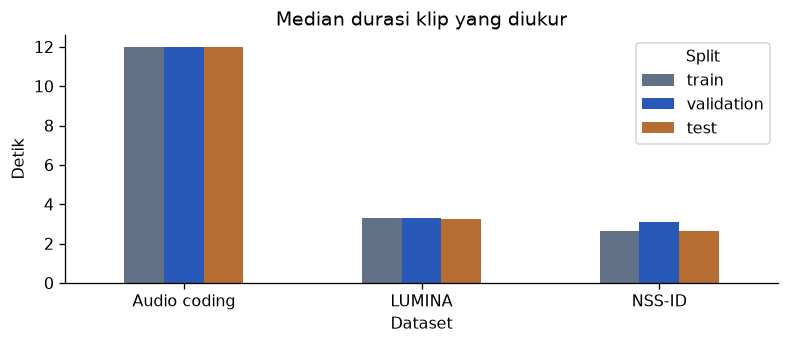

In [3]:
from scripts.notebook_asr import SAMPLE_RATE, read_audio
from scripts.notebook_training import AUDIO

audio_records = []
if shutil.which("ffmpeg"):
    for dataset, (folder, _, media_key, group_key) in AUDIO.items():
        for split, frame in tables[dataset].items():
            sample = frame.sample(min(2, len(frame)), random_state=SEED)
            times = [len(read_audio(BASE / folder / item)) / SAMPLE_RATE for item in sample[media_key]]
            audio_records.append({"Dataset": dataset, "Split": split, "Klip": len(frame),
                                  "Grup unik": frame[group_key].nunique(),
                                  "Klip diukur": len(times), "Durasi contoh (detik)": np.median(times),
                                  "Median kata referensi": frame["transcript"].str.split().str.len().median()})
if not audio_records:
    audio_records = replay.get("notebook_eda", {}).get("audio", [])
if audio_records:
    audio_stats = pd.DataFrame(audio_records)
    display(audio_stats.round(2))
    axis = audio_stats.pivot(index="Dataset", columns="Split", values="Durasi contoh (detik)").reindex(
        columns=SPLITS
    ).plot.bar(rot=0, color=PALETTE, figsize=(8, 2.8), title="Median durasi klip yang diukur")
    axis.set_ylabel("Detik")
    plt.show()
else:
    print("Manifest audio dan FFmpeg diperlukan untuk menghitung statistik durasi.")

- LUMINA dan NSS-ID mengukur ucapan Indonesia umum. Audio coding menguji istilah domain, dengan subtitle otomatis sebagai acuan yang dapat mengandung salah dengar.
- Durasi diukur pada maksimal dua klip acak per split. Median kata referensi dihitung dari seluruh split lokal.
- Setiap korpus menyumbang subset latih. Validasi memakai rata-rata WER per korpus agar korpus besar tidak mendominasi pemilihan epoch.

## 04 · Eksplorasi pasangan teks dan strategi penggunaan data

D:\KULIAH\NLP\Text Sumarization_3A_TA_NLP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Dataset,Split,Contoh lolos,Contoh diukur,Median token masukan,Median token target,Masukan >256,Target >72
0,IndoSum,train,14261,100,450.500000,95.000000,91.0%,99.0%
1,IndoSum,validation,750,100,439.000000,95.000000,93.0%,99.0%
2,IndoSum,test,3762,100,453.500000,96.000000,90.0%,96.0%
3,Tutorial coding,train,46,46,43.000000,21.000000,0.0%,0.0%
4,Tutorial coding,validation,6,6,77.500000,19.000000,0.0%,0.0%
5,Tutorial coding,test,9,9,83.000000,17.000000,0.0%,0.0%


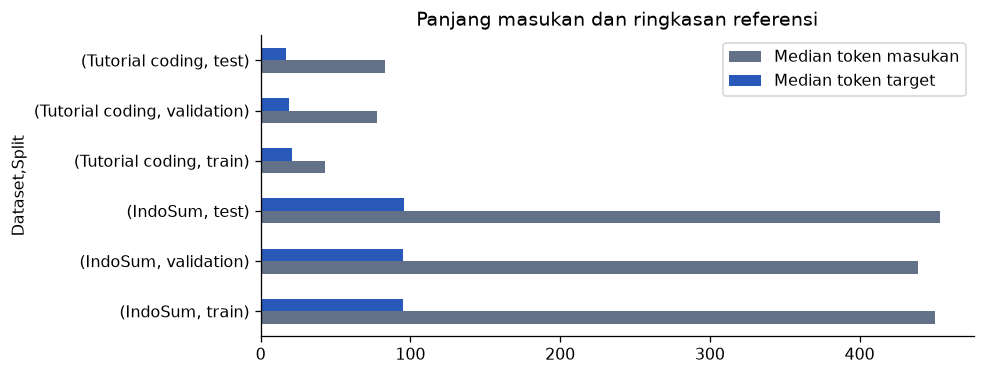

train {'original_synthetic': 28, 'python_youtube': 18, 'crosstask': 10}
validation {'python_youtube': 6}
test {'python_youtube': 9}


In [4]:
from src.seq2seq_models import load_tokenizer, model_files

try:
    mbart_path = model_files("mbart")
except OSError:
    mbart_path = None
tokenizer = load_tokenizer("mbart", mbart_path) if mbart_path else None
text_records = []
if tokenizer:
    for dataset in ("IndoSum", "Tutorial coding"):
        for split, frame in tables[dataset].items():
            valid = frame[frame["text"].str.strip().ne("") & frame["summary"].str.strip().ne("")]
            if dataset == "Tutorial coding":
                valid = valid[valid["source_lang"].eq("id_ID") & valid["target_lang"].eq("id_ID")]
            if valid.empty:
                continue
            sample = valid.sample(min(100, len(valid)), random_state=SEED)
            source_k = np.array([len(ids) for ids in tokenizer(sample["text"].tolist(), verbose=False).input_ids])
            target_k = np.array([len(ids) for ids in tokenizer(text_target=sample["summary"].tolist(), verbose=False).input_ids])
            text_records.append({"Dataset": dataset, "Split": split, "Contoh lolos": len(valid),
                                 "Contoh diukur": len(sample), "Median token masukan": float(np.median(source_k)),
                                 "Median token target": float(np.median(target_k)),
                                 "Masukan >256": float((source_k > 256).mean()),
                                 "Target >72": float((target_k > 72).mean())})
if not text_records:
    text_records = replay.get("notebook_eda", {}).get("text", [])
if text_records:
    token_stats = pd.DataFrame(text_records)
    display(token_stats.style.format({"Masukan >256": "{:.1%}", "Target >72": "{:.1%}"}))
    token_stats.set_index(["Dataset", "Split"])[["Median token masukan", "Median token target"]].plot.barh(
        color=PALETTE[:2], figsize=(8, 3.4), title="Panjang masukan dan ringkasan referensi")
    plt.show()
for split, frame in tables["Tutorial coding"].items():
    print(split, frame["source"].value_counts().to_dict())

- IndoSum mengajarkan pola peringkasan artikel. Coding Video Mix memberi contoh instruksi, kode dan detail yang perlu dipertahankan.
- **Strategi langsung** memakai latih coding. **Strategi bertahap** belajar dari IndoSum lebih dulu, lalu melanjutkan dari checkpoint tahap itu pada latih coding. Kedua strategi menggunakan validasi dan uji coding yang sama.
- Contoh sintetis proyek hanya masuk latih. Pasangan CrossTask berbahasa Inggris tersaring oleh syarat `id_ID → id_ID`. Data sintetis regresi OCR tetap dipakai untuk uji terkontrol terpisah.
- Persentase pemotongan berasal dari token SentencePiece mBART dan dibaca sebagai perkiraan pada sampel.

## 05 · Audio ke representasi log-Mel

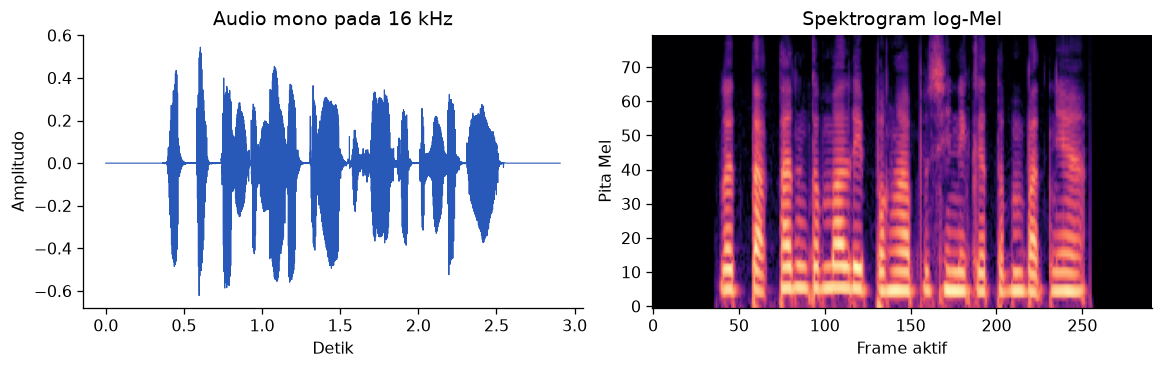

46,524 sampel | 2.91 detik | bentuk fitur (80, 3000) | 291 frame aktif


In [5]:
from scripts.notebook_asr import SAMPLE_RATE, read_audio

if "train" in tables["NSS-ID"] and shutil.which("ffmpeg"):
    from transformers import WhisperFeatureExtractor

    example = tables["NSS-ID"]["train"].iloc[0]
    wave = read_audio(BASE / "nss-id" / example["audio_path"])
    matrix = WhisperFeatureExtractor()(wave, sampling_rate=SAMPLE_RATE, return_tensors="np").input_features[0]
    length = min(matrix.shape[1], round(len(wave) / 160))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.1), layout="constrained")
    axes[0].plot(np.arange(len(wave)) / SAMPLE_RATE, wave, color=PALETTE[1], linewidth=0.7)
    axes[0].set(title="Audio mono pada 16 kHz", xlabel="Detik", ylabel="Amplitudo")
    axes[1].imshow(matrix[:, :length], origin="lower", aspect="auto", cmap="magma")
    axes[1].set(title="Spektrogram log-Mel", xlabel="Frame aktif", ylabel="Pita Mel")
    plt.show()
    print(f"{len(wave):,} sampel | {len(wave) / SAMPLE_RATE:.2f} detik | bentuk fitur {matrix.shape} | {length} frame aktif")

- FFmpeg mengambil jalur audio dan menyamakannya ke mono 16 kHz. Gelombang berisi 16.000 sampel per detik.
- Whisper base menghitung STFT dengan jendela 400 sampel dan langkah 160 sampel. Energi dipetakan ke 80 pita Mel, lalu diubah ke skala log. Bentuk masukannya 80 × 3.000 untuk jendela 30 detik.
- Encoder membaca fitur akustik. Decoder memakai konteks encoder untuk menebak token Indonesia dan menghasilkan penanda waktu saat transkripsi. [Paper Whisper](https://arxiv.org/abs/2212.04356)

## 06 · Fine-tuning Whisper dari tiga korpus

,test,train,validation
Audio coding,2,2,2
LUMINA,2,2,2
NSS-ID,2,2,2


openai/whisper-base | smoke | cpu | epoch terpilih 1 | LR 1e-05


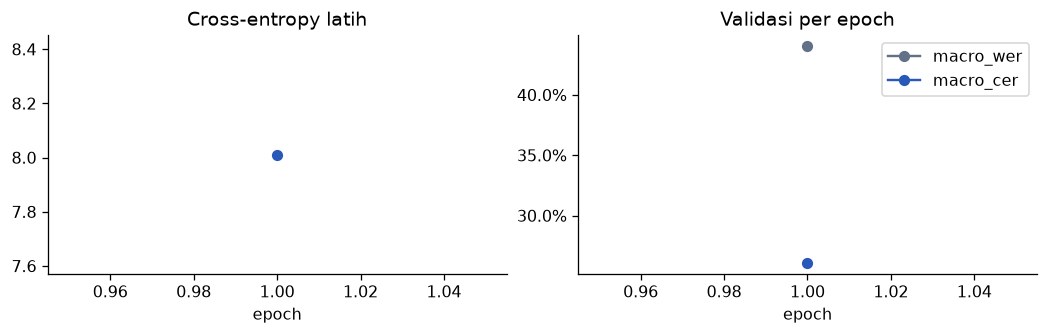

In [6]:
whisper_dir = RUN / "whisper"
if TRAIN:
    execute("scripts.notebook_training", "whisper", "--profile", MODE, "--output", whisper_dir)
    whisper_report = read_json(whisper_dir / "report.json")
else:
    whisper_report = replay.get("mixed_whisper")

if whisper_report:
    display(pd.DataFrame(whisper_report["splits"]).T)
    print(f"{whisper_report['base']} | {whisper_report['mode']} | {whisper_report['device']} | "
          f"epoch terpilih {whisper_report['best_epoch']} | LR {whisper_report['learning_rate']:g}")
    stages = pd.DataFrame(whisper_report["history"]).set_index("epoch")
    fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), layout="constrained")
    stages["loss"].plot(ax=axes[0], marker="o", color=PALETTE[1], title="Cross-entropy latih")
    stages[["macro_wer", "macro_cer"]].plot(ax=axes[1], marker="o", color=PALETTE[:2], title="Validasi per epoch")
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    plt.show()
else:
    print("Laporan pelatihan campuran belum tersedia.")

- Korpus digabung pada split latih dan diacak ulang per epoch. Batas per korpus pada pilot adalah 16 latih, 8 validasi dan 12 uji, sejauh data tersedia.
- Whisper base membekukan sebagian besar bobot. Hanya proyeksi Q dan V self-attention serta cross-attention pada decoder terakhir yang ikut dioptimasi.
- AdamW `1e-5`, batch 1, weight decay `0,01`, batas gradien `1,0`. Warmup sekitar 10% update lalu LR turun linear. Pada smoke yang sangat pendek pembulatan warmup dapat menghasilkan 0 langkah.
- Pilih macro-WER validasi terendah dengan macro-CER sebagai pemecah seri. Pilot berhenti setelah dua epoch berturut-turut tanpa perbaikan.

## 07 · Video utuh dan hasil transkripsi

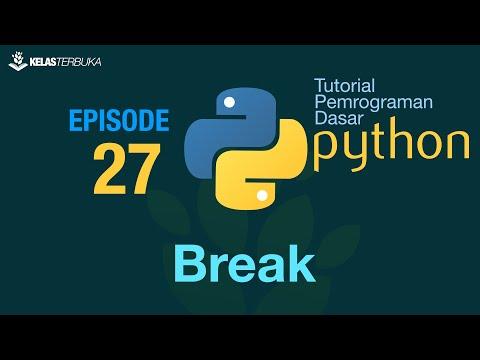

[Break pada perulangan Python](https://www.youtube.com/watch?v=B6scLunzn0I) · [Kode pemateri](https://raw.githubusercontent.com/kelasterbuka/Python3.x_Dasar_Programming/master/Episode%2027%20-%20Break/Main.py)

08:39 | 20 segmen | data/raw/models/faster-whisper-small
openai/whisper-base adaptasi (whisper) menghasilkan 11 segmen. Rentang satu segmen melebihi 45 detik. Audio dibaca ulang dengan data/raw/models/faster-whisper-small.


,start,end,transcript
0,15.54,44.18,Assalamualaikum warahmatullahi wabarakatuh te...
1,44.62,74.10,"oke ini adalah kondisinya, oke, nah si aksi i..."
2,74.66,100.34,"oke atau gini lah, ini kita coba ulangi ya, i..."
3,101.08,120.04,"ini biar jelas ya, karena kita pake dipiton, ..."
4,121.08,148.98,"nah sama nih, masuk ke sini, terus dia ada ak..."


In [7]:
from urllib.parse import parse_qs, urlsplit
from IPython.display import YouTubeVideo
from src.youtube import youtube_watch_url

raw_url = os.getenv("NLP_MULTIMODAL_YOUTUBE_URL", "").strip()
test_video = os.getenv("NLP_MULTIMODAL_VIDEO", "").strip()
test_url = youtube_watch_url(raw_url) if raw_url else ("" if test_video else holdout[0]["video_url"])
test_id = parse_qs(urlsplit(test_url).query).get("v", [""])[0]
run_video = bool(raw_url or test_video or GEMINI_LIMIT or os.getenv("NLP_NOTEBOOK_FRESH_VIDEO") == "1"
                 or os.getenv("NLP_MULTIMODAL_RUN") == "1" or os.getenv("NLP_MULTIMODAL_TRANSCRIPT")
                 or os.getenv("NLP_NOTEBOOK_WHISPER_CHECKPOINT") or os.getenv("NLP_NOTEBOOK_MBART_WEIGHTS"))
prepared_path = RUN / "video_prepared.json"
archived_video = replay["whole_video"]

def video_time(value):
    minutes, seconds = divmod(int(value), 60)
    return f"{minutes:02d}:{seconds:02d}"

def video_stage(stage, *args):
    execute("scripts.notebook_video_ablation", stage, "--prepared", prepared_path, *args)
    return read_json(prepared_path)

if run_video:
    media = ROOT / "outputs/notebooks/multimodal/break.mp4"
    cache = ROOT / "outputs/notebooks/heldout-small" / f"{test_id}.json"
    flags = ["--url", test_url] if test_url else []
    if test_video or (test_id == holdout[0]["id"] and media.is_file()):
        flags += ["--video", test_video or media]
    transcript = os.getenv("NLP_MULTIMODAL_TRANSCRIPT", "").strip()
    if transcript:
        flags += ["--transcript", transcript]
    elif TRAIN or os.getenv("NLP_NOTEBOOK_WHISPER_CHECKPOINT"):
        flags += ["--whisper-checkpoint", os.getenv("NLP_NOTEBOOK_WHISPER_CHECKPOINT") or whisper_dir / "checkpoint"]
    elif test_id and cache.is_file():
        flags += ["--transcript", cache]
    transcribed = video_stage("transcribe", *flags)
    cues = transcribed["cues"]
else:
    transcribed = archived_video["prepared"]
    cues = [{"start": cue["start"], "end": cue["end"], "transcript": cue["original"]}
            for part in transcribed["parts"] for cue in part["trace"]]
chosen = next((item for item in holdout if item["id"] == test_id), None)
if test_id:
    display(YouTubeVideo(test_id, width=560, height=315))
if chosen:
    display(Markdown(f"[{chosen['title']}]({test_url}) · [Kode pemateri]({chosen['code_url']})"))
print(f"{video_time(transcribed['duration'])} | {len(cues)} segmen | {transcribed['whisper']}")
if retry := transcribed.get("transcription_retry"):
    print(f"{retry['model']} menghasilkan {retry['segments']} segmen. "
          f"{retry['reason']}. Audio dibaca ulang dengan {transcribed['whisper']}.")
display(pd.DataFrame(cues).head(5))

- FFprobe memeriksa durasi. Whisper atau cache dari video yang sama menyediakan teks dan waktu tiap segmen.
- Mode replay menampilkan jejak video nyata yang sudah tersimpan. Jika checkpoint adaptasi tidak memberi segmen atau satu segmen melampaui 45 detik, audio dibaca ulang dengan backend Faster Whisper dan pergantian dicatat.
- Skor video hanya tersedia bila ID sumber memiliki fakta dan detail acuan dalam manifest.

## 08 · Cleaning, normalisasi dan pembagian konteks

,Bagian,Mulai,Selesai,Segmen,Kata asli,Kata bersih
0,1,00:00,00:55,1,86,86
1,2,00:55,01:50,2,129,129
2,3,01:50,02:45,3,183,183
3,4,02:45,03:40,1,70,70
4,5,03:40,04:35,2,143,142
5,6,04:35,05:30,2,129,129
6,7,05:30,06:25,2,134,134
7,8,06:25,07:20,3,119,119
8,9,07:20,08:15,2,135,135
9,10,08:15,08:39,2,43,43


dirapikan    20
Name: count, dtype: int64

,original,cleaned,status
0,Assalamualaikum warahmatullahi wabarakatuh te...,Assalamualaikum warahmatullahi wabarakatuh tem...,dirapikan
1,"oke ini adalah kondisinya, oke, nah si aksi i...","oke ini adalah kondisinya, oke, nah si aksi it...",dirapikan
2,"oke atau gini lah, ini kita coba ulangi ya, i...","oke atau gini lah, ini kita coba ulangi ya, in...",dirapikan
3,"ini biar jelas ya, karena kita pake dipiton, ...","ini biar jelas ya, karena kita pake dipiton, o...",dirapikan
4,"nah sama nih, masuk ke sini, terus dia ada ak...","nah sama nih, masuk ke sini, terus dia ada aks...",dirapikan
5,"oke ini kalau continue ya, kalau break dia ak...","oke ini kalau continue ya, kalau break dia aka...",dirapikan


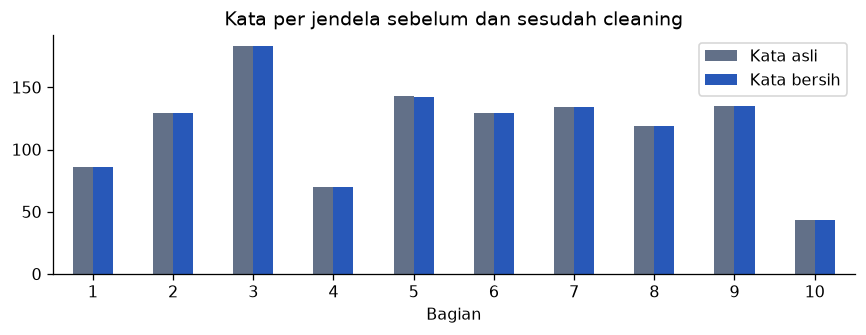

In [8]:
prepared = video_stage("clean") if run_video else archived_video["prepared"]
trace = [cue for part in prepared["parts"] for cue in part["trace"]]
part_stats = pd.DataFrame([{
    "Bagian": part["id"], "Mulai": video_time(part["start"]), "Selesai": video_time(part["end"]),
    "Segmen": len(part["trace"]),
    "Kata asli": sum(len(cue["original"].split()) for cue in part["trace"]),
    "Kata bersih": len(part["speech"].split()),
} for part in prepared["parts"]])
display(part_stats)
display(pd.Series([row["status"] for row in trace], dtype="object").value_counts())
examples = [row for row in trace if row["status"] != "dipertahankan"][:6]
if examples:
    display(pd.DataFrame(examples)[["original", "cleaned", "status"]])
part_stats.plot.bar(x="Bagian", y=["Kata asli", "Kata bersih"], color=PALETTE[:2], rot=0,
                    figsize=(9, 2.7), title="Kata per jendela sebelum dan sesudah cleaning")
plt.show()

- Rapikan spasi dan pengisi pembuka. Hilangkan pengisi mandiri dan duplikat yang bertumpang tindih, lalu normalisasi ejaan teknis dengan aturan yang mempertimbangkan konteks.
- Pertahankan negasi, angka, nama fungsi, parameter, operator, serta urutan ucapan. Stemming dan penghapusan stopword bisa menghilangkan detail itu.
- Bagi transkrip ke jendela 55 detik berdasarkan titik tengah segmen. Simpan teks asli, teks bersih, status dan penanda waktu. Rujukan seperti “ini” masih memerlukan bukti dari ucapan sekitar atau layar.

## 09 · Bukti visual dari OCR lokal

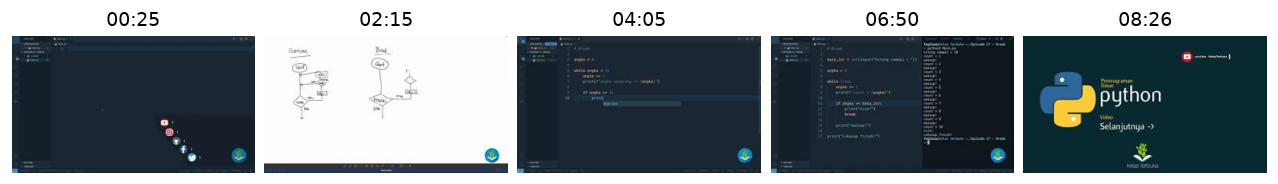

,Bagian,Frame,Baris OCR
0,1,6,1
1,2,6,2
2,3,6,1
3,4,6,6
4,5,6,30
5,6,8,48
6,7,8,52
7,8,7,61
8,9,6,62
9,10,7,20


,part,loop,condition,increment,uses_input
0,6,while angka < 5:,angka == 3,angka += 1,False
1,7,while True:,angka == 3,angka += 1,False
2,8,while True:,angka == data_int,angka += 1,True
3,9,while True:,angka == data_int,angka += 1,True
4,9,while angka < 5:,angka == 3,angka += 1,False


In [9]:
from base64 import b64decode
from io import BytesIO
from PIL import Image

if run_video:
    roi = os.getenv("NLP_MULTIMODAL_ROI",
                    "0.225 0.115 0.61 0.90" if test_id == holdout[0]["id"] else "0 0 1 1").split()
    prepared = video_stage("ocr", "--roi", *roi)
previews = [part["preview"] for part in prepared["parts"] if "preview" in part]
if previews:
    fig, axes = plt.subplots(1, len(previews), figsize=(11, 2.5), squeeze=False, layout="constrained")
    for axis, item in zip(axes[0], previews, strict=True):
        with Image.open(BytesIO(b64decode(item["image"]))) as image:
            axis.imshow(image)
        axis.set_title(video_time(item["second"]))
        axis.axis("off")
    plt.show()
frame_table = pd.DataFrame([{"Bagian": part["id"], "Frame": len(part["frames"]),
                             "Baris OCR": sum(len(frame["lines"]) for frame in part["frames"])}
                            for part in prepared["parts"]])
display(frame_table)
findings = pd.DataFrame(prepared["actions"])
if findings.empty:
    print("OCR lokal belum menemukan pola aksi yang lolos pemeriksaan antar-frame.")
else:
    display(findings[["part", "loop", "condition", "increment", "uses_input"]])

- FFmpeg mengambil beberapa frame setiap bagian. Area editor dipotong, diubah ke grayscale dan diperbesar sebelum Tesseract membaca teks.
- Sistem menyimpan hasil baca serta waktu frame. Pola kondisi dan instruksi kode yang berulang pada lebih dari satu frame menjadi bukti yang dapat dipakai untuk memperjelas ucapan.
- Tabel menampilkan cakupan frame dan baris. Cuplikan layar memperlihatkan dampak ukuran teks, crop dan kualitas video terhadap OCR.

## 10 · Gemini multimodal sebelum ringkasan

In [10]:
if run_video:
    prepared = video_stage("gemini", "--gemini-max-requests", GEMINI_LIMIT)
vision = prepared["gemini"]
display(pd.Series({"Status": vision["status"], "Model": vision.get("model", "—"),
                   "Permintaan": vision["requests"], "Bagian dikirim": len(vision.get("parts_sent", [])),
                   "Bukti terverifikasi": len(vision["verified"]), "Token API": vision.get("token_count")}))
if vision["verified"]:
    display(pd.DataFrame(vision["verified"])[["part", "quote", "code"]])

Status                 Respons Gemini diterima.
Model                     gemini-3.5-flash-lite
Permintaan                                    1
Bagian dikirim                                2
Bukti terverifikasi                           1
Token API                                  5413
dtype: object

,part,quote,code
0,8,"integer ya, data integer, integer, terus kita ...","data_int = int(input(""hitung sampai = ""))"


- Gemini menerima transkrip bersih dan dua foto editor yang berdekatan. Gemini mengaitkan satu kutipan dengan satu baris kode, lalu pipeline memeriksa kecocokannya dengan bukti lokal.
- Gemini berjalan dalam inferensi dengan temperatur 0, keluaran terstruktur, dan batas permintaan. Batas bawaan 0. Aktifkan lewat `NLP_GEMINI_MAX_REQUESTS` sebelum membuka kernel. [Dokumentasi multimodal Gemini](https://ai.google.dev/gemini-api/docs/image-understanding)
- Bukti yang lolos masuk ke jalur C sebelum mBART. Kegagalan akses, kuota, atau bukti kosong dicatat di sini agar grafik akhirnya tidak menampilkan skor rekaan.

## 11 · Token, ID dan embedding mBART

In [11]:
example = "Gunakan break ketika penghitung mencapai 3."
if tokenizer:
    import torch
    from transformers import AutoConfig

    model_config = AutoConfig.from_pretrained(mbart_path, local_files_only=True)
    ids = tokenizer(example).input_ids
    token_table = pd.DataFrame({"Token": tokenizer.convert_ids_to_tokens(ids), "ID kosakata": ids})
    with torch.no_grad():
        weights = torch.load(mbart_path / "pytorch_model.bin", mmap=True, weights_only=True, map_location="cpu")
        embedding = weights["model.shared.weight"][ids, :4].clone().numpy()
        del weights
    for index in range(embedding.shape[1]):
        token_table[f"E[{index}]"] = embedding[:, index]
    token_example = {"rows": token_table.to_dict("records"), "d_model": model_config.d_model,
                     "heads": model_config.encoder_attention_heads, "language_id": tokenizer.lang_code_to_id["id_ID"]}
else:
    token_example = replay.get("notebook_eda", {}).get("tokens")
if token_example:
    display(pd.DataFrame(token_example["rows"]).round(4))
    print(f"ID bahasa id_ID = {token_example['language_id']} | dimensi embedding per token = "
          f"{token_example['d_model']} | attention heads = {token_example['heads']}")
else:
    print("Cache tokenizer dan checkpoint diperlukan untuk menampilkan embedding aktual.")

,Token,ID kosakata,E[0],E[1],E[2],E[3]
0,id_ID,250032,-0.0362,0.0153,-0.0087,-0.0209
1,▁Gunakan,180206,-0.0191,0.0133,0.0844,0.0098
2,▁break,36356,0.0065,-0.0923,0.0473,0.0297
3,▁ketika,6458,-0.0648,-0.0533,-0.0247,0.0222
4,▁peng,10048,-0.0437,-0.0434,-0.0496,0.0222
5,hitung,68183,0.0084,-0.0546,-0.0004,-0.0130
6,▁mencapai,31457,-0.0249,-0.0273,0.0027,-0.0293
7,▁3.,1031,0.0192,-0.0482,-0.0680,0.0109
8,</s>,2,-0.0230,-0.0406,-0.0443,-0.0292


ID bahasa id_ID = 250032 | dimensi embedding per token = 1024 | attention heads = 16


- SentencePiece memecah teks menjadi subword, lalu tokenizer memetakan tiap token ke ID. Tag `id_ID` dipakai pada masukan dan keluaran.
- Setiap ID mengambil satu baris dari matriks embedding pralatih. Tabel menunjukkan empat komponen aktual dari vektor penuh. Encoder menambahkan informasi posisi agar kata yang sama di posisi berbeda punya konteks berbeda.
- Pelatihan memakai batas 256 token sumber dan 72 token target. Bagian panjang dibatasi saat encoding. [Checkpoint mBART-large-50](https://huggingface.co/facebook/mbart-large-50)

## 12 · Perhitungan self-attention, causal mask dan cross-attention

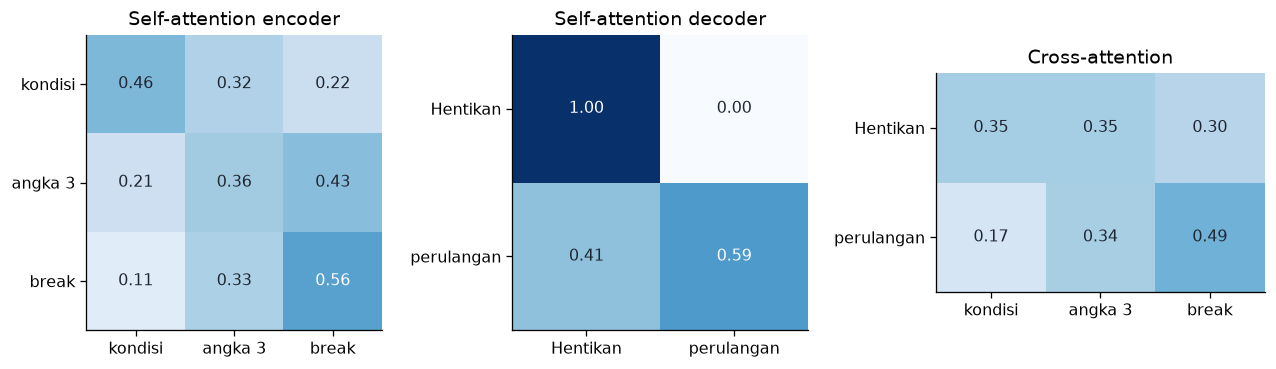

Contoh vektor konteks cross-attention untuk token pertama [0.529 0.795]


In [12]:
def attention(query, key, value, *, causal=False):
    scores = query @ key.T / np.sqrt(query.shape[1])
    if causal:
        scores = np.where(np.triu(np.ones(scores.shape, dtype=bool), 1), -np.inf, scores)
    stabilized = np.exp(scores - scores.max(axis=1, keepdims=True))
    weights = stabilized / stabilized.sum(axis=1, keepdims=True)
    return weights, weights @ value

source = np.array([[1.0, 0.0], [0.5, 1.0], [0.0, 1.5]])
target_demo = np.array([[1.0, 0.5], [0.0, 1.0]])
names_src = ["kondisi", "angka 3", "break"]
names_tgt = ["Hentikan", "perulangan"]
views = [
    ("Self-attention encoder", source, source, source, False, names_src, names_src),
    ("Self-attention decoder", target_demo, target_demo, target_demo, True, names_tgt, names_tgt),
    ("Cross-attention", target_demo, source, source, False, names_tgt, names_src),
]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1), layout="constrained")
for axis, (title, q, k, v, mask, rows, columns) in zip(axes, views, strict=True):
    weights, context = attention(q, k, v, causal=mask)
    axis.imshow(weights, vmin=0, vmax=1, cmap="Blues")
    axis.set(xticks=range(len(columns)), xticklabels=columns, yticks=range(len(rows)), yticklabels=rows, title=title)
    for y, x in np.ndindex(weights.shape):
        axis.text(x, y, f"{weights[y, x]:.2f}", ha="center", va="center",
                  color="white" if weights[y, x] > 0.55 else "#202631")
plt.show()
print("Contoh vektor konteks cross-attention untuk token pertama", context[0].round(3))

- **Encoder self-attention** membentuk Q, K dan V dari token sumber, sehingga kata seperti “kondisi” dapat merujuk ke “angka 3” dan “break”.
- **Decoder self-attention** memakai causal mask. Skor token yang berada di depan diganti dengan $-infty$, sehingga bobotnya menjadi nol.
- **Cross-attention** mengambil Q dari decoder, serta K dan V dari encoder. Bobotnya $operatorname{softmax}(QK^	op/sqrt{d_k})$ dan hasil konteksnya adalah bobot dikali V. Setiap baris dijumlahkan menjadi 1.
- Heatmap memakai vektor contoh 2 dimensi agar hitungannya terbaca. Bobot mBART diperoleh dari proyeksi terlatih di setiap head. [Paper Transformer](https://arxiv.org/abs/1706.03762)

## 13 · Fine-tuning dan pemilihan strategi mBART

,test,train,validation
coding_video_mix,2,2,2
indosum,2,2,2


,Strategi,Tahap,Epoch,Loss latih,ROUGE-L validasi
0,Coding langsung,coding_video_mix,1,6.609,0.060
1,IndoSum → coding,indosum,1,1.406,0.543
2,IndoSum → coding,coding_video_mix,1,6.609,0.060


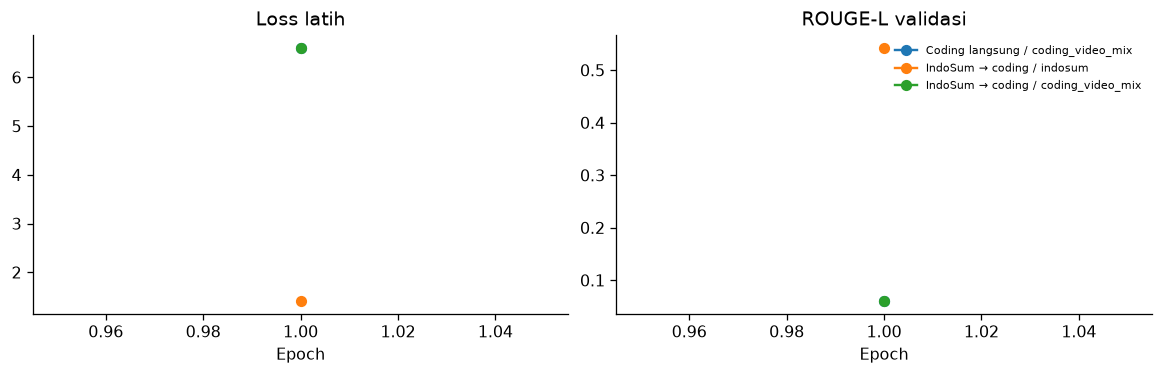

smoke | cuda:0 | LR 2e-05 | 2,097,152 bobot aktif | terpilih mBART dasar


In [13]:
mbart_dir = RUN / "mbart"
if TRAIN:
    execute("scripts.notebook_training", "mbart", "--profile", MODE, "--device", MBART_DEVICE,
            "--output", mbart_dir, python=MBART_PYTHON)
    mbart_report = read_json(mbart_dir / "report.json")
else:
    mbart_report = replay.get("staged_mbart")

strategies = {"base": "mBART dasar", "coding": "Coding langsung", "indosum_coding": "IndoSum → coding"}
if mbart_report:
    display(pd.DataFrame(mbart_report["splits"]).T)
    curves = [{"Strategi": strategies[key], "Tahap": stage["dataset"],
               "Epoch": epoch["epoch"], "Loss latih": epoch["loss"], "ROUGE-L validasi": epoch["validation"]["rougeL"]}
              for key, variant in mbart_report["variants"].items()
              for stage in variant["stages"] for epoch in stage["history"]]
    history = pd.DataFrame(curves)
    display(history.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.15), layout="constrained")
    for (route, domain), series in history.groupby(["Strategi", "Tahap"], sort=False):
        for axis, metric in zip(axes, ("Loss latih", "ROUGE-L validasi"), strict=True):
            axis.plot(series["Epoch"], series[metric], marker="o", label=f"{route} / {domain}")
            axis.set(title=metric, xlabel="Epoch")
    axes[1].legend(fontsize=7, frameon=False)
    plt.show()
    print(f"{mbart_report['mode']} | {mbart_report['device']} | LR {mbart_report['learning_rate']:g} | "
          f"{mbart_report['parameter_count']:,} bobot aktif | terpilih {strategies[mbart_report['winner']]}")
else:
    print("Laporan adaptasi mBART belum tersedia. Latih ulang dengan mode smoke atau pilot.")

- Ketiga strategi berawal dari revisi `facebook/mbart-large-50` yang sama. Pelatihan membuka bobot Q dan V pada cross-attention decoder terakhir secara langsung.
- AdamW dengan LR tetap `2e-5`, batch fisik 1, akumulasi maksimal 8, weight decay `0,01`, dan clipping `1,0`. LR kecil membatasi besar perubahan bobot pralatih. Akumulasi memperbesar batch efektif tanpa memuat semua contoh sekaligus. Forward memakai BF16 dan pembaruan optimizer disimpan dalam FP32.
- Decoder melihat token referensi yang sudah digeser satu posisi. Cross-entropy merata-ratakan $-log p(y_tmid y_{<t},x)$ pada token target. Contoh: jika model memberi probabilitas 0,25 pada token benar, kontribusi loss adalah 1,39.
- Tahap IndoSum dipilih berdasarkan ROUGE-L validasi. Tahap coding dan pemenang antarrute mengutamakan recall detail teknis pada validasi coding, lalu ROUGE-L. Pilot berhenti setelah dua epoch tanpa perbaikan.

## 14 · Inferensi A/B/C pada video yang sama

In [14]:
variant_labels = {"transcript": "A · Transkrip", "ocr": "B · Transkrip + OCR",
                  "gemini": "C · Transkrip + OCR + Gemini"}
if run_video:
    outcome_path = RUN / "video_summary.json"
    flags = ["--output", outcome_path, "--device", MBART_DEVICE]
    if TRAIN or os.getenv("NLP_NOTEBOOK_MBART_WEIGHTS"):
        flags += ["--mbart-weights", os.getenv("NLP_NOTEBOOK_MBART_WEIGHTS") or mbart_dir / "selected.pt"]
    execute("scripts.notebook_video_ablation", "summarize", "--prepared", prepared_path, *flags, python=MBART_PYTHON)
    outcome = read_json(outcome_path)
else:
    outcome = archived_video["outcome"]

variants = outcome["variants"]
display(pd.DataFrame([{"Jalur": name, "Jumlah poin": len(variants[key]["rows"]) if key in variants else None,
                       "Detik": round(variants[key]["seconds"], 2) if key in variants else None,
                       "Status": "Selesai" if key in variants else vision["status"]}
                      for key, name in variant_labels.items()]))
print(outcome["checkpoint"], "|", outcome["precision"])

,Jalur,Jumlah poin,Detik,Status
0,A · Transkrip,5,7.59,Selesai
1,B · Transkrip + OCR,5,9.30,Selesai
2,C · Transkrip + OCR + Gemini,5,10.07,Selesai


facebook/mbart-large-50@4ef55a20b36c6903b832e38f0604ab4bdf22c7d6 · base · smoke | BF16 · cpu


- A memakai transkrip bersih. B menambahkan bukti OCR lokal. C memakai bukti tambahan Gemini yang terverifikasi. Semua jalur yang tersedia memakai model dan aturan decoding yang sama.
- mBART menghasilkan kandidat per langkah dengan beam search 2. Pemeriksaan sumber menjaga angka dan ekspresi kode. Saat kandidat gagal, sistem dapat memakai rumusan yang didukung sumber. Tidak setiap poin akhir merupakan keluaran mentah model.
- Hasil replay video mempunyai identitas checkpoint sendiri. Untuk memakai checkpoint terbaru, aktifkan pelatihan dan inferensi video dalam satu sesi.

## 15 · Evaluasi transkripsi dan kesalahan pengenalan

,Dataset,Varian,cer,wer
0,Audio coding,adapted,45.1%,75.8%
1,Audio coding,base,45.1%,75.8%
2,LUMINA,adapted,26.3%,66.7%
3,LUMINA,base,26.3%,66.7%
4,NSS-ID,adapted,18.6%,50.0%
5,NSS-ID,base,18.6%,50.0%


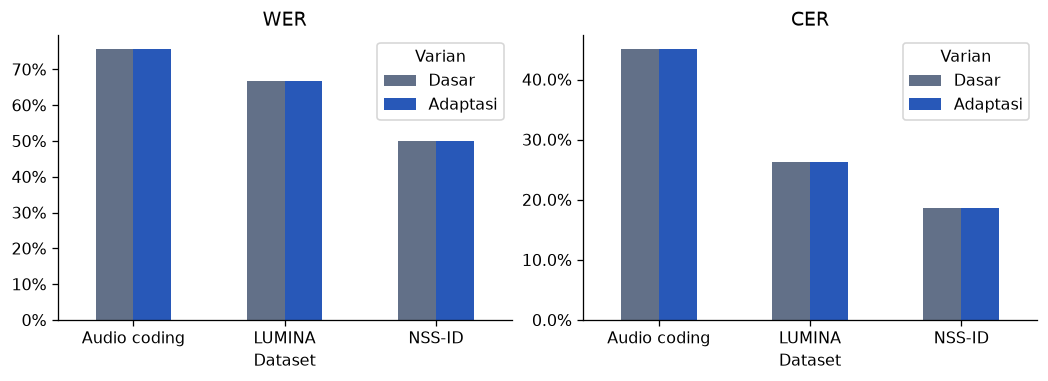

,wer,cer
Varian,,
base,64.1%,30.0%
adapted,64.1%,30.0%


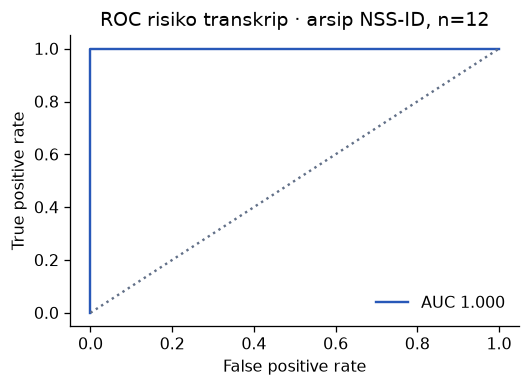

In [15]:
if whisper_report:
    errors = pd.DataFrame([{"Dataset": name, "Varian": key, **values}
                           for name, test in whisper_report["test"].items() for key, values in test.items()])
    display(errors.style.format({"wer": "{:.1%}", "cer": "{:.1%}"}))
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
    for axis, metric in zip(axes, ("wer", "cer"), strict=True):
        errors.pivot(index="Dataset", columns="Varian", values=metric)[["base", "adapted"]].rename(
            columns={"base": "Dasar", "adapted": "Adaptasi"}
        ).plot.bar(ax=axis, rot=0, color=PALETTE[:2], title=metric.upper())
        axis.yaxis.set_major_formatter(PercentFormatter(1))
    plt.show()
    comparison = errors.groupby("Varian")[["wer", "cer"]].mean().loc[["base", "adapted"]]
    display(comparison.style.format("{:.1%}"))

from scripts.notebook_asr import risk_roc

audit = pd.DataFrame(replay["asr"]["NSS-ID"]["audit"]).rename(columns={"wer_adaptasi": "wer"})
roc = risk_roc(audit, threshold=0.25)
if roc:
    fpr, tpr, auc, n = roc
    fig, axis = plt.subplots(figsize=(4.5, 3.25), layout="constrained")
    axis.plot(fpr, tpr, color=PALETTE[1], label=f"AUC {auc:.3f}")
    axis.plot([0, 1], [0, 1], color=PALETTE[0], linestyle=":")
    axis.set(title=f"ROC risiko transkrip · arsip NSS-ID, n={n}", xlabel="False positive rate",
             ylabel="True positive rate")
    axis.legend(frameon=False)
    plt.show()

- WER dan CER menghitung (substitusi + penghapusan + penyisipan) dibagi jumlah unit acuan. WER memakai kata dan CER memakai karakter. Skor lebih rendah lebih baik.
- Subtitle otomatis pada Audio coding memberi acuan perkiraan. Skor identik pada subset kecil belum cukup untuk menyimpulkan manfaat adaptasi.
- ROC adalah analisis tambahan dari arsip NSS-ID, terpisah dari eksperimen gabungan. Label risiko memakai WER ≥ 25% dan skor risiko memakai negatif log-probabilitas rerata. Kurva mengukur pemisahan klip berisiko oleh skor tersebut.

## 16 · Evaluasi model peringkas dan pembanding

,rouge1,rouge2,rougeL,detail_recall,loss,latency_ms,truncated
mBART dasar,0.14155,0.016667,0.078238,0.8,9.53125,4683.9012,0
Coding langsung,0.14155,0.016667,0.078238,0.8,9.53125,4680.8859,0
IndoSum → coding,0.14155,0.016667,0.078238,0.8,9.53125,4857.80415,0


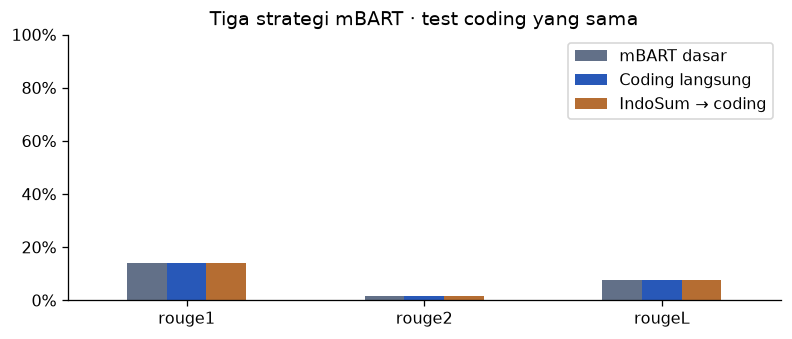

**Arsip lokal tiga arsitektur dasar**

,Dataset,Model,Contoh uji,rouge1,rouge2,rougeL
0,indosum,facebook/mbart-large-50,9,0.679,0.605,0.647
1,indosum,google/mt5-small,9,0.026,0.014,0.023
2,indosum,indobenchmark/indobart,9,0.630,0.549,0.599
3,coding_video_mix,facebook/mbart-large-50,9,0.198,0.041,0.146
4,coding_video_mix,google/mt5-small,9,0.012,0.000,0.012
5,coding_video_mix,indobenchmark/indobart,9,0.193,0.043,0.146


**Benchmark IndoSum yang diterbitkan, skala 0–100**

,Model,ROUGE-1,ROUGE-2,ROUGE-L
0,mBART-large-50,74.65,70.43,72.54
1,mT5-small,74.04,69.64,71.89
2,IndoBART,70.67,65.59,68.18


In [16]:
scores = ("rouge1", "rouge2", "rougeL")
if mbart_report:
    variants_eval = pd.DataFrame({strategies[key]: variant["test"]
                                  for key, variant in mbart_report["variants"].items()}).T
    display(variants_eval[[*scores, "detail_recall", "loss", "latency_ms", "truncated"]].round(3))
    axis = variants_eval[list(scores)].T.plot.bar(rot=0, color=PALETTE, figsize=(8, 3), ylim=(0, 1),
                                                   title="Tiga strategi mBART · test coding yang sama")
    axis.yaxis.set_major_formatter(PercentFormatter(1))
    plt.show()
else:
    print("Skor uji strategi mBART muncul setelah pelatihan menghasilkan laporan.")

base_models = pd.DataFrame([{"Dataset": row["dataset"], "Model": row["hub"],
                             "Contoh uji": row["counts"]["test"], **{metric: row["base"][metric] for metric in scores}}
                            for row in replay["seq2seq"]["reports"]])
display(Markdown("**Arsip lokal tiga arsitektur dasar**"))
display(base_models.round(3))
paper_indosum = pd.DataFrame([
    ["mBART-large-50", 74.65, 70.43, 72.54],
    ["mT5-small", 74.04, 69.64, 71.89],
    ["IndoBART", 70.67, 65.59, 68.18],
], columns=["Model", "ROUGE-1", "ROUGE-2", "ROUGE-L"])
display(Markdown("**Benchmark IndoSum yang diterbitkan, skala 0–100**"))
display(paper_indosum)

- ROUGE-1, ROUGE-2 dan ROUGE-L adalah F1 dari kecocokan kata, pasangan kata berurutan, dan subsekuens kata terpanjang. Skor lokal memakai skala 0–1. Recall detail memeriksa unsur seperti nama fungsi, operator, dan angka acuan.
- Loss mengukur probabilitas token referensi selama forward. ROUGE menghitung kemiripan ringkasan yang benar-benar dihasilkan. Periksa keduanya bersama detail teknis.
- Tabel arsip tiga arsitektur berasal dari inferensi lokal checkpoint dasar. Tabel skor 70-an berasal dari eksperimen IndoNLG pada IndoSum. Perbedaan dataset, checkpoint, serta evaluasi membuat angkanya perlu dibaca dalam konteks masing-masing. [Tabel 5 IndoNLG](https://aclanthology.org/2021.emnlp-main.699.pdf)

## 17 · Dampak OCR dan Gemini pada video utuh

,Cakupan fakta,Detail kode,ROUGE-1,ROUGE-2,ROUGE-L
Jalur,,,,,
A · Transkrip,1.0,0.0,0.343,0.165,0.303
B · Transkrip + OCR,1.0,1.0,0.286,0.091,0.232
C · Transkrip + OCR + Gemini,1.0,1.0,0.270,0.092,0.216


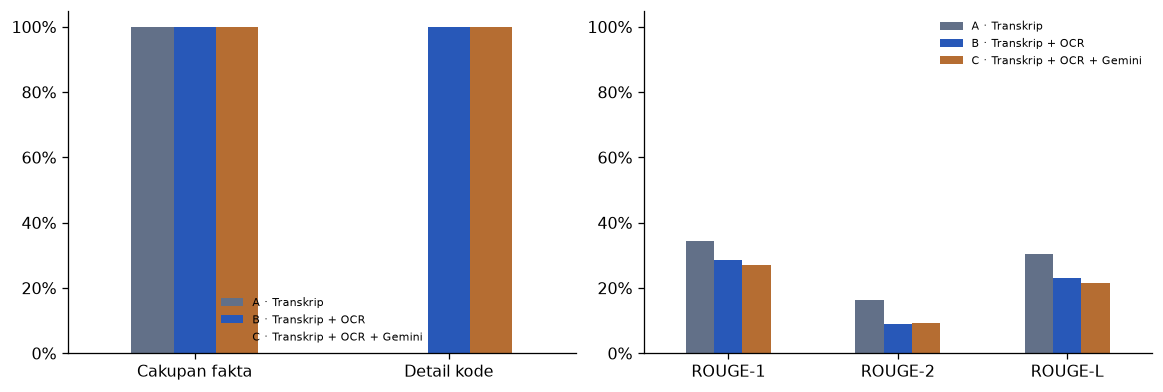

,Cakupan fakta,Detail kode,ROUGE-1,ROUGE-2,ROUGE-L
Jalur,,,,,
B · Transkrip + OCR,0.0,1.0,-0.058,-0.074,-0.071
C · Transkrip + OCR + Gemini,0.0,1.0,-0.073,-0.073,-0.087


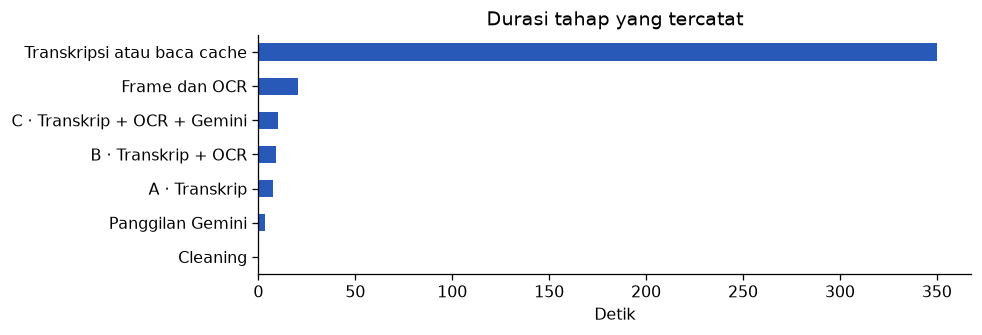

**Cakupan uji regresi preprocessing**

,Sampel,Jenis,Peran,Fakta lama,Fakta revisi,Kode lama,Kode revisi,Status
0,Break pada perulangan Python,Video publik,Pengembangan,1/3,1/3,0/4,0/4,ready
1,Format string di Python,Video publik,Uji eksploratif,0/5,2/5,—,—,ready
2,Instruksi di dalam kalimat pembuka,Sintetis,Uji regresi,0/1,1/1,0/1,1/1,unclear
3,Istilah string salah tangkap dan instruksi ter...,Sintetis,Uji regresi,0/4,4/4,0/2,2/2,unclear
4,Demonstrasi percabangan tanpa ucapan,Sintetis,Uji regresi,0/3,3/3,0/3,3/3,no_speech
5,Narasi memasak sebagai kontrol negatif,Sintetis,Uji regresi,—,—,—,—,out_of_scope


In [17]:
rows = []
for key, name in variant_labels.items():
    metrics = variants.get(key, {}).get("scores")
    if metrics:
        rows.append({"Jalur": name, "Cakupan fakta": metrics["coverage"], "Detail kode": metrics["detail_recall"],
                     "ROUGE-1": metrics["rouge1"], "ROUGE-2": metrics["rouge2"], "ROUGE-L": metrics["rougeL"]})
if rows:
    comparison_video = pd.DataFrame(rows).set_index("Jalur")
    display(comparison_video.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
    for axis, columns in zip(axes, (["Cakupan fakta", "Detail kode"], ["ROUGE-1", "ROUGE-2", "ROUGE-L"]), strict=True):
        comparison_video[columns].dropna(how="all", axis=1).T.plot.bar(ax=axis, color=PALETTE, rot=0, ylim=(0, 1.05))
        axis.yaxis.set_major_formatter(PercentFormatter(1))
        axis.legend(fontsize=7, frameon=False)
    plt.show()
    if len(rows) > 1:
        display(comparison_video.subtract(comparison_video.iloc[0]).iloc[1:].round(3))
else:
    print("Fakta acuan untuk video ini belum tersedia.")
if "gemini" not in variants:
    print("C tanpa skor,", vision["status"])

timing = {"Frame dan OCR": prepared["ocr_seconds"]}
for key, label in (("transcript_seconds", "Transkripsi atau baca cache"), ("cleaning_seconds", "Cleaning")):
    if key in prepared:
        timing[label] = prepared[key]
if vision["requests"]:
    timing["Panggilan Gemini"] = vision["seconds"]
timing.update({variant_labels[key]: item["seconds"] for key, item in variants.items()})
pd.Series(timing).sort_values().plot.barh(color=PALETTE[1], figsize=(8, 2.7), xlabel="Detik",
                                          title="Durasi tahap yang tercatat")
plt.show()

cases = replay["preprocessing_evaluation"]["cases"]
if os.getenv("NLP_PREPROCESSING_EVAL") == "1":
    audit_path = RUN / "preprocessing" / "report.json"
    execute("scripts.notebook_preprocessing_eval", "--output", audit_path)
    cases = read_json(audit_path)["cases"]
display(Markdown("**Cakupan uji regresi preprocessing**"))
def hits(entries, flag):
    return f"{sum(row[flag] for row in entries)}/{len(entries)}" if entries else "—"

display(pd.DataFrame([{"Sampel": item["title"], "Jenis": item["kind"], "Peran": item["role"],
                       "Fakta lama": hits(item["baseline"]["facts"], "covered"),
                       "Fakta revisi": hits(item["revised"]["facts"], "covered"),
                       "Kode lama": hits(item["baseline"]["details"], "present"),
                       "Kode revisi": hits(item["revised"]["details"], "present"),
                       "Status": item["status"]} for item in cases]))

- Cakupan fakta mengukur berapa fakta referensi yang dijumpai. Detail kode memeriksa bentuk yang lebih spesifik. Tabel selisih memakai A sebagai titik acuan.
- Perubahan pada satu video memberi bukti untuk video tersebut. Jalur C memerlukan respons yang terverifikasi agar dampak Gemini dapat dihitung.
- Uji regresi membandingkan aturan lama dan revisi pada video publik serta kasus sintetis, termasuk narasi bising, pembicaraan di luar domain, dan informasi yang hanya muncul di layar.

## 18 · Luaran akhir dan ekspor

In [18]:
from html import escape
from IPython.display import HTML
from src.code_text import highlight_code

def timed_transcript(title, key):
    lines = "\n".join(f"[{video_time(cue['start'])}–{video_time(cue['end'])}] {cue[key].strip()}"
                      for cue in trace if cue[key].strip())
    return f"<details><summary>{escape(title)}</summary><pre style='white-space:pre-wrap'>{escape(lines)}</pre></details>"

display(HTML(timed_transcript("Transkrip asli lengkap", "original") +
             timed_transcript("Transkrip bersih lengkap", "cleaned")))
exports = []
for key, name in variant_labels.items():
    display(Markdown(f"### {name}"))
    if key not in variants:
        display(Markdown(f"Jalur belum menghasilkan bukti tambahan. {vision['status']}"))
        continue
    points = variants[key]["rows"]
    if not points:
        display(Markdown("Belum ada langkah yang cukup jelas dalam bukti yang tersedia."))
    else:
        items = "".join(f"<li>{highlight_code(point['summary'])}</li>" for point in points)
        display(HTML(f"<ul>{items}</ul>"))
    exports.extend({"variant": key, "point": index, "summary": point["summary"], "checkpoint": outcome["checkpoint"]}
                   for index, point in enumerate(points, 1))
if run_video:
    pd.DataFrame(trace).to_csv(RUN / "transcripts.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(exports, columns=["variant", "point", "summary", "checkpoint"]).to_csv(
        RUN / "summary_points.csv", index=False, encoding="utf-8-sig"
    )
    print("Ekspor tersimpan di", RUN.relative_to(ROOT))
    print("API lokal menerima satu teks dalam JSON melalui POST /summarize.")

### A · Transkrip

### B · Transkrip + OCR

### C · Transkrip + OCR + Gemini

- Buka transkrip untuk melihat seluruh teks dan penanda waktu. Ringkasan disajikan sebagai daftar langkah berurutan yang bisa dibaca sendiri.
- Eksekusi video baru menulis `transcripts.csv`, `summary_points.csv` dan laporan JSON. Identitas model tercatat bersama hasil sehingga bisa dipakai kembali dari Python atau sebagai masukan untuk integrasi berikutnya.